### Specs:
- CPU: Intel Core Ultra 9 (x86-64)
- Numpy version: 2.5.4
- RAM: 16GB

In [1]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
print(np.__version__)

2.5.4


In [2]:
def DFT_mat(N):
    r = np.arange(N)
    n = r[:, np.newaxis]
    k = r[np.newaxis, :]
    W = np.exp(-2j * np.pi * k * n / N)
    return W

W4 = DFT_mat(4)
print(np.round(W4, 2))

[[ 1.+0.j  1.+0.j  1.+0.j  1.+0.j]
 [ 1.+0.j  0.-1.j -1.-0.j -0.+1.j]
 [ 1.+0.j -1.-0.j  1.+0.j -1.-0.j]
 [ 1.+0.j -0.+1.j -1.-0.j  0.-1.j]]


In [3]:
def customDFT(img):
    M,N = img.shape
    w_m = DFT_mat(M)
    w_n = DFT_mat(N)
    F = w_m @ img @ w_n.T
    return F

img = Image.open("A2\\Q1,4\\q1.png")
F_custom = customDFT(np.array(img))
F_np = np.fft.fft2(np.array(img))
max_error = np.max(np.abs(F_custom - F_np))
print("Max error: ", max_error)

Max error:  1.128441482403766e-06


# (a) Conjugate Symmetry
For a real-valued image $f(x,y)$ of size $N \times N$, the forward
2-D DFT is
$$
F(u,v)=\sum_{x=0}^{N-1}\sum_{y=0}^{N-1}
f(x,y)e^{-j2\pi(ux+vy)/N}.
$$

Taking the complex conjugate gives
$$
F^*(u,v)=\sum_{x=0}^{N-1}\sum_{y=0}^{N-1}
f^*(x,y)e^{+j2\pi(ux+vy)/N}.
$$

Since the image is given to be real, $f^*(x,y)=f(x,y)$. Therefore,
$$
F^*(u,v)
=\sum_{x=0}^{N-1}\sum_{y=0}^{N-1}
f(x,y)e^{-j2\pi((-u)x+(-v)y)/N}
=F(-u,-v).
$$

Thus, every frequency coefficient has a conjugate partner at the opposite frequency. With same magnitude and opposite phases:
$$
|F(u,v)|=|F((-u)\bmod N,(-v)\bmod N)|.
$$

### Which spectral region is redundant?
For even $N$, retaining columns $v=1,\ldots,N/2-1$ is sufficient to recover the entire spectrum using conjugate symmetry. Columns $v=N/2-1,\ldots,N-1$ are redundant. Additional symmetry exists within the boundary columns $v=1,\ldots,N/2-1$
$$
F(u,v)=F^*((-u)\bmod N,\;N-v).
$$

There is additional redundancy within the retained boundary columns
$v=0$ and $v=N/2$:

$$
F(u,v)=F^*((-u)\bmod N,v).
$$


### Why display the full magnitude spectrum?

A full magnitude spectrum displays positive and negative spatial frequencies together. This makes it easier to interpret. It presents the complete frequency plane in a consistent and visually interpretable form.


In [4]:
M, N = np.array(img).shape
u = np.arange(M)[:, None]
v = np.arange(N)[None, :]

dx, dy = 6, -7
shifted = np.roll(np.array(img), (dx, dy), axis=(0, 1))

F = customDFT(np.array(img))
measured = customDFT(shifted)

predicted = F * np.exp(-2j * np.pi * (u*dx/M + v*dy/N))

print("Maximum complex error:", np.max(np.abs(measured - predicted)))
print("Mean complex error:", np.mean(np.abs(measured - predicted)))

coords = [(0, 0), (2, 1), (6, 7), (6, 9), (4, 2)]
rows = []

for a, b in coords:
    rows.append({
        "Frequency": (a, b),
        "Measured magnitude": np.abs(measured[a, b]),
        "Predicted magnitude": np.abs(predicted[a, b]),
        "Complex error": np.abs(measured[a, b] - predicted[a, b]),
        "Phase error": np.angle(measured[a, b] * np.conj(predicted[a, b]))
    })

display(pd.DataFrame(rows))

Maximum complex error: 1.4269643543568407e-06
Mean complex error: 1.98795661743632e-09


,Frequency,Measured magnitude,Predicted magnitude,Complex error,Phase error
0,"(0, 0)",3.383250e+07,3.383250e+07,0.000000e+00,0.000000e+00
1,"(2, 1)",9.211444e+05,9.211444e+05,1.927016e-09,-8.631889e-16
2,"(6, 7)",2.452610e+05,2.452610e+05,3.285530e-10,-1.181135e-15
3,"(6, 9)",1.713821e+05,1.713821e+05,3.231050e-10,9.740704e-16
4,"(4, 2)",9.702062e+05,9.702062e+05,1.171407e-09,0.000000e+00


### 2-D Spatial Shift Theroem
The 2-D Spatial Shift Theorem (or 2-D Fourier Shift Theorem) states that a shift or translation of a function in the spatial (or image) domain results in a linear phase shift in the 2-D Fourier transform domain, while leaving the magnitude (amplitude) spectrum unchanged

### Emperical proof
We shifted the image by (6,-7) (with proper circular shift mapping [using roll]). Using the max and average error along with the quantitive comparision table we can see the emperical proof of the 2-D spatial shift Theorem. We calculated the theoretical predictions and measure the real values and show that the magnitude different is negligible (python floating point error) and only a phase shift (difference) is present. 

In [5]:
M,N = np.array(img).shape
g = np.ones((3, 3)) / 9
g_padded = np.zeros((M, N))
g_padded[:3, :3] = g
F = customDFT(np.array(img))
G = customDFT(g_padded)

conv_spatial = np.zeros((M, N), dtype=float)
for i in range(M):
    for j in range(N):
        for m in range(3):
            for n in range(3):
                conv_spatial[i, j] += np.array(img)[(i - m) % M, (j - n) % N] * g[m, n]

CONV = customDFT(conv_spatial)
prod = F * G
max_error_conv = np.max(np.abs(CONV - prod))
avg_error_conv = np.mean(np.abs(CONV - prod))
print("Max error in convolution: ", max_error_conv)
print("Average error in convolution: ", avg_error_conv)
sample_coords = [(0, 0), (2, 1), (6, 7), (6, 9), (4, 2)]
table = []
for ui, vi in sample_coords:
    conv_val = CONV[ui, vi]
    prod_val = prod[ui, vi]
    
    table.append({
        "coord": (ui, vi),
        "Conv Mag": np.abs(conv_val),
        "Prod Mag": np.abs(prod_val),
        "Diff_mag": np.abs(np.abs(conv_val) - np.abs(prod_val)),
        "Conv Phase": np.angle(conv_val),
        "Prod Phase": np.angle(prod_val),
        "Diff_phase": np.angle(conv_val) - np.angle(prod_val)
    })
df = pd.DataFrame(table)
print(df)

Max error in convolution:  7.590066412104121e-07
Average error in convolution:  9.106744288627625e-10
    coord      Conv Mag      Prod Mag      Diff_mag  Conv Phase  Prod Phase  \
0  (0, 0)  3.383250e+07  3.383250e+07  0.000000e+00    0.000000    0.000000   
1  (2, 1)  9.209133e+05  9.209133e+05  1.164153e-09   -2.417014   -2.417014   
2  (6, 7)  2.442161e+05  2.442161e+05  0.000000e+00    2.761552    2.761552   
3  (6, 9)  1.703776e+05  1.703776e+05  1.164153e-10    1.936093    1.936093   
4  (4, 2)  9.692324e+05  9.692324e+05  8.149073e-10   -1.972754   -1.972754   

     Diff_phase  
0  0.000000e+00  
1 -4.440892e-16  
2 -4.440892e-16  
3  4.440892e-16  
4 -6.661338e-16  


### 2-D Circular Convolution Theroem
the 2-D circular convolution of two finite 2-D signals (or matrices) in the spatial domain corresponds to the point-by-point (element-wise) multiplication of their 2-D Discrete Fourier Transforms (DFTs) in the frequency domain, and vice versa

### Emperical proof
We created a 3x3 averaging filter. We calculate the spatial convolution of the provided image with this filter. We compared the FFT of this convoluted image with the element-wise product of the DFT of image and filter independently. Using the max and average error along with the quantitive comparision table, we show how the values are identical (same magnitude and phase) thus emperically proving the circular convolution theorem

In [6]:
N = 128
x = np.arange(N)[:, None]
y = np.arange(N)[None, :]

sinusoids = [
    {"x_cycles": 5,  "y_cycles": 5, "amp": 69.0, "phase": 0.45},
    {"x_cycles": 19, "y_cycles": 19,  "amp": 20.0, "phase": -1.20},
    {"x_cycles": 25, "y_cycles": 30, "amp": 42.0, "phase": 2.10}
]
synthetic_img = np.zeros((N, N), dtype=float)
for s in sinusoids:
    spatial_carrier = 2.0 * np.pi * (s["x_cycles"] * x + s["y_cycles"] * y) / N
    synthetic_img += s["amp"] * np.cos(spatial_carrier + s["phase"])


F_synthetic = customDFT(synthetic_img)
mag_spectrum = np.abs(F_synthetic)


mag_search = mag_spectrum.copy()
mag_search[0, 0] = 0.0
recovered_params = []
for _ in range(len(sinusoids)):
    peak_idx = np.argmax(mag_search)
    pu, pv = np.unravel_index(peak_idx, (N, N))
    if pu > N // 2:
        u_rec = (N - pu) % N
        v_rec = (N - pv) % N
        comp_val = np.conj(F_synthetic[pu, pv])
    else:
        u_rec = pu
        v_rec = pv
        comp_val = F_synthetic[pu, pv]
        
    amp_rec = (2.0 * np.abs(comp_val)) / (N * N)
    phase_rec = np.angle(comp_val)
    
    recovered_params.append({
        "x_cycles": u_rec,
        "y_cycles": v_rec,
        "amp": amp_rec,
        "phase": phase_rec
    })
    
    conj_u = (N - pu) % N
    conj_v = (N - pv) % N
    mag_search[pu, pv] = 0.0
    mag_search[conj_u, conj_v] = 0.0

for entry in recovered_params:
    print(f"Recovered: x_cycles={entry['x_cycles']}, y_cycles={entry['y_cycles']}, amp={entry['amp']:.5f}, phase={entry['phase']:.5f}")

Recovered: x_cycles=5, y_cycles=5, amp=69.00000, phase=0.45000
Recovered: x_cycles=25, y_cycles=30, amp=42.00000, phase=2.10000
Recovered: x_cycles=19, y_cycles=19, amp=20.00000, phase=-1.20000


### (c) Sinusoid Parameter Recovery - Theoretical Spatial Frequency Resolution Limit ($\Delta f$)

2-D discrete grid of dimensions $N \times N$ with spatial sampling intervals $\Delta x = \Delta y = 1$ pixel. The physical spatial window extent (image dimension) is $L = N \cdot \Delta x = N$ pixels. This is because the basis functions of the Discrete Fourier Transform (DFT) are complex exponentials orthogonal over the discrete interval $[0, N-1]$ and for these basis sequences to complete integer cycles over the finite support $N$ and maintain orthogonality:
$$
\sum_{n=0}^{N-1} e^{j \frac{2\pi}{N} (k_1 - k_2) n} = N \delta[k_1 - k_2]
$$
the fundamental frequency spacing in terms of spatial cycles per image:
$$
\Delta f_{\text{image}} = 1 \text{ cycle/image}
$$
In physical spatial frequency units (cycles per pixel / cycles per unit length):
$$
\Delta f_{\text{pixel}} = \frac{1}{N \cdot \Delta x} = \frac{1}{N} \text{ cycles/pixel}
$$

### Prediction photo
![title](Q1-written-prediction.jpeg)

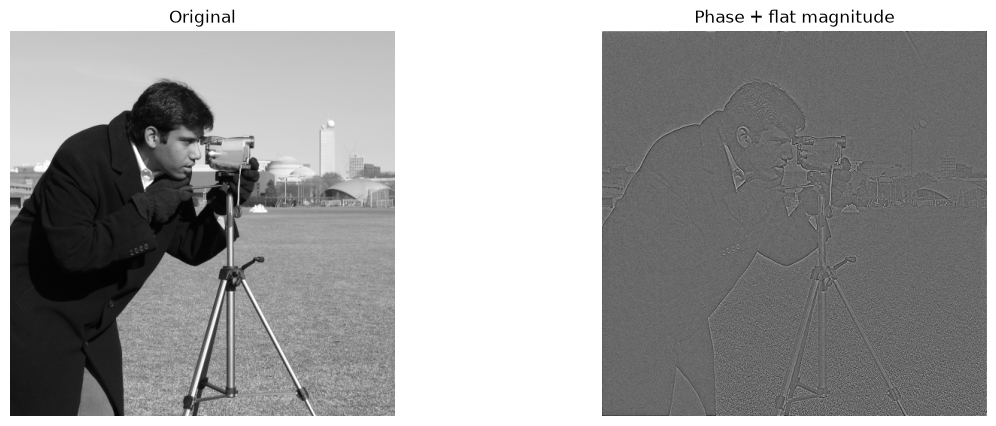

In [7]:
F = customDFT(np.array(img))
mag = np.abs(F)
phase = np.angle(F)

flat_mag = np.ones_like(mag)
rec_a = np.real(np.fft.ifft2(flat_mag * np.exp(1j * phase)))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(img, cmap='gray');          ax[0].set_title('Original')
ax[1].imshow(rec_a, cmap='gray');        ax[1].set_title('Phase + flat magnitude')
for a in ax: a.axis('off')
plt.show()

### Observation and Reconciliation
The phase-only reconstruction preserves much of the recognizable spatial structure, including object boundaries and relative feature positions, while losing the original intensity distribution.

This agrees with the pre-implementation prediction. However, a flat magnitude spectrum does not necessarily produce an exact edge map. Removing the magnitude information changes the relative contributions of all frequency components and may introduce ringing and negative values.

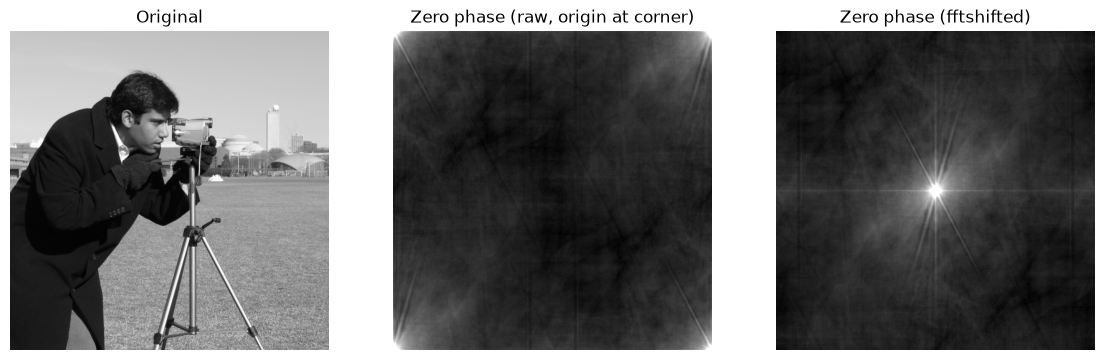

In [8]:
rec_b = np.real(np.fft.ifft2(mag))
rec_b_centered = np.fft.fftshift(rec_b)

fig, ax = plt.subplots(1, 3, figsize=(14, 5))
ax[0].imshow(img, cmap='gray');                 ax[0].set_title('Original')
ax[1].imshow(rec_b, cmap='gray', vmax=np.percentile(rec_b, 99.9))
ax[1].set_title('Zero phase (raw, origin at corner)')
ax[2].imshow(rec_b_centered, cmap='gray', vmax=np.percentile(rec_b, 99.9))
ax[2].set_title('Zero phase (fftshifted)')
for a in ax: a.axis('off')
plt.show()

(b) We recieve |F(u,v)| is real and even, because |F| is symmetric for a real image. So the reconstruction is real and even-symmetric: f'(x,y) = f'(−x,−y) (circularly). With zero phase, all sinusoids are cosines aligned at the origin, so they add constructively there and nowhere else. Hence we observe bright peak at the origin, a symmetric pattern around it, and no recognizable object layout or edges.

In [9]:
N = np.array(img).shape[0]
M = 5

k = -np.ones((M, M))
k[2, 2] = 24

def freq_filter(img, k, P):
    img = np.array(img)
    N = img.shape[0]
    M = k.shape[0]

    kp = np.zeros((P, P))
    kp[:M, :M] = k

    # Correctly shift kernel center to origin
    kp = np.roll(kp, (-(M // 2), -(M // 2)), axis=(0, 1))

    ip = np.zeros((P, P))
    ip[:N, :N] = img

    out = np.real(np.fft.ifft2(customDFT(ip) * customDFT(kp)))
    return out[:N, :N]

P = N + M - 1

circ = freq_filter(img, k, N)
lin  = freq_filter(img, k, P)


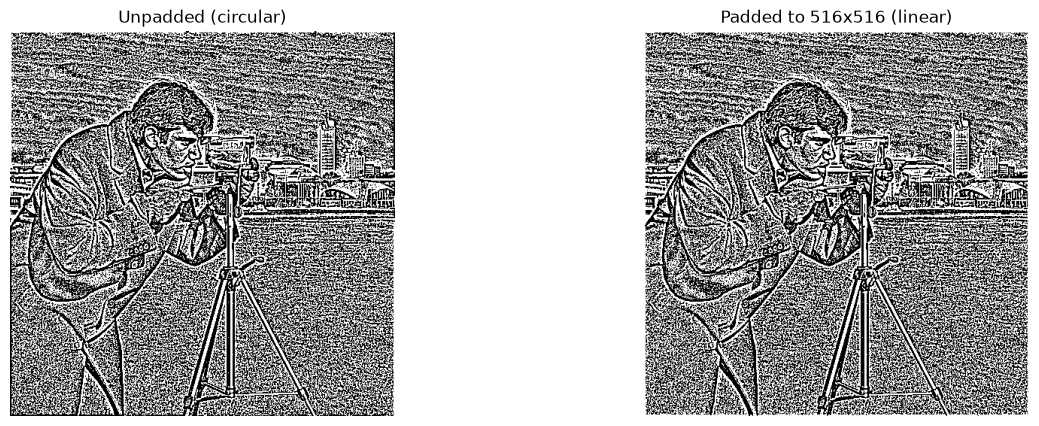

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].imshow(circ, cmap='gray', vmin=-1, vmax=1); ax[0].set_title('Unpadded (circular)')
ax[1].imshow(lin,  cmap='gray', vmin=-1, vmax=1); ax[1].set_title(f'Padded to {P}x{P} (linear)')
for a in ax: a.axis('off')
plt.show()

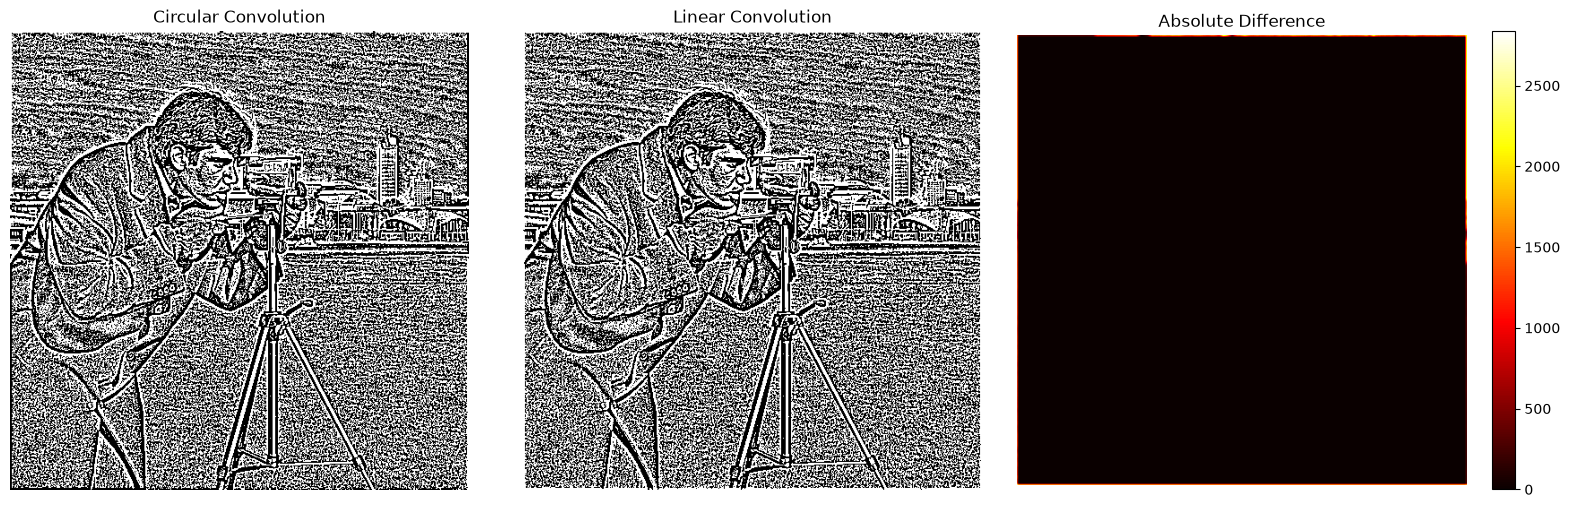

Maximum absolute difference: 2836.999999999624
Interior maximum difference: 1.5543264453299344e-09


In [11]:
diff = np.abs(circ - lin)
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].imshow(circ, cmap='gray', vmin=-1, vmax=1)
ax[0].set_title('Circular Convolution')
ax[1].imshow(lin, cmap='gray', vmin=-1, vmax=1)
ax[1].set_title('Linear Convolution')
im = ax[2].imshow(diff, cmap='hot')
ax[2].set_title('Absolute Difference')
fig.colorbar(im, ax=ax[2], fraction=0.046)
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()
print("Maximum absolute difference:", diff.max())
print("Interior maximum difference:",
      diff[M//2:-M//2+1, M//2:-M//2+1].max())


In [12]:
N = np.array(img).shape[0]
M = k.shape[0]
P = N + M - 1

memory_factor = (P / N)**2
runtime_factor = (P / N)**2 * (np.log2(P) / np.log2(N))

print(f"Original dimensions: {N} x {N}")
print(f"Padded dimensions: {P} x {P}")
print(f"Memory factor: {memory_factor:.6f}")
print(f"Extra memory: {(memory_factor - 1)*100:.4f}%")
print(f"Runtime complexity factor: {runtime_factor:.6f}")

Original dimensions: 512 x 512
Padded dimensions: 516 x 516
Memory factor: 1.015686
Extra memory: 1.5686%
Runtime complexity factor: 1.016953


### Part 1.3 Observation

A $(5*5)$ Laplacian kernel was applied to the image using frequency-domain multiplication under two conditions: without padding (\(N\times N\)) and with zero-padding (\((N+M-1)\times(N+M-1)\)).

In circular convolution, pixels outside the image boundaries are replaced by pixels from the opposite side of the image due to periodic extension. In contrast, zero-padded linear convolution treats pixels outside the original image as zero.

The absolute difference image highlights these boundary artifacts, while the interior region remains numerically identical up to floating-point precision.

**Proof and computation trade off**

### Proof
the minimum DFT dimensions required to guarantee full linear convolution are $P_x = N_x + M_x - 1$ and
$P_y = N_y + M_y - 1.$


For an image $f[x,y]$ of size $N_x\times N_y$ and a kernel $h[x,y]$ of size $M_x\times M_y$, their linear convolution can have nonzero samples only within

$$
0\le x\le N_x+M_x-2,
$$

$$
0\le y\le N_y+M_y-2.
$$

Thus, the full linear-convolution output has dimensions

$$
(N_x+M_x-1)\times(N_y+M_y-1).
$$

Circular convolution periodically folds this output along each axis independently.

To prevent aliasing in either direction, the padding must satisfy

$$
P_x\ge N_x+M_x-1,
\qquad
P_y\ge N_y+M_y-1.
$$

### (b) Trade off
**Memory factor**: Size goes from $N*N$ to $(N+M-1)*(N+M-1)$ hence the additional memory allocation factor is ((N+M−1)/N)².

**Runtime**: Runtime goes from O(N² log N) to O(P² log P). Since P = N + M − 1 ≤ 2N, this is the same
asymptotic order with a constant-factor increase of (P/N)² · (log P / log N).

**scipy.signal.fftconvolve** uses exactly this rule: shape = s1+s2−1 (the minimal L from (a)),
then P_f = next_fast_len(shape, real=True) ≥ L (still alias-free, but with a fast factorization),
zero-pads implicitly multiplies the spectra, applies irfftn, and crops to
'full'/'same'/'valid'. Its cost is therefore (P_f/N)² in memory and (P_f/N)²·log(P_f)/log(N) in time.